# Wisconsin Breast Cancer — Data Mining Notebook
**Pre-processing → Classification → Clustering (K-Means) → Association Rules (Support & Confidence)**

**Dataset:** Breast Cancer Wisconsin (Diagnostic) — 569 samples, 30 numeric features computed from digitised images of fine-needle aspirates (FNA) of breast masses. Each sample is labelled **Malignant** or **Benign**.

**Contents**
1. Setup & loading the data
2. Exploratory data analysis
3. Data pre-processing
   - 3.1 Cleaning checks
   - 3.2 Standardization / Normalization
   - 3.3 Transformation
   - 3.4 Aggregation
   - 3.5 Discretization & Binarization
   - 3.6 Sampling
4. Classification
5. Clustering — K-Means (from scratch + scikit-learn)
6. Association rules — support, confidence, lift
7. Summary

## 1. Setup & loading the data

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler,
                                   PowerTransformer, KBinsDiscretizer, Binarizer, Normalizer)
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, silhouette_score,
                             adjusted_rand_score, homogeneity_score)
from sklearn.utils import resample

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 40)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [5]:
# Load the Breast Cancer Wisconsin (Diagnostic) dataset
bc = load_breast_cancer(as_frame=True)
df = bc.frame.copy()

# In scikit-learn: 0 = malignant, 1 = benign.  We re-encode so that  Malignant = 1 (the "positive" class)
df["diagnosis"] = df["target"].map({0: "Malignant", 1: "Benign"})
df["label"] = (df["target"] == 0).astype(int)      # 1 = Malignant, 0 = Benign
df = df.drop(columns="target")
df.to_excel("breast_canc.xlsx")
feature_cols = list(bc.feature_names)
print("Shape:", df.shape)
df.head()

Shape: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis,label
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant,1


### Feature naming
The 30 features are 10 base measurements, each computed three ways:

| Group | Meaning | Example |
|---|---|---|
| `mean ...` | mean of the measurement over all cells in the image | `mean radius` |
| `... error` | standard error of the measurement | `radius error` |
| `worst ...` | mean of the 3 largest values (the "worst" cells) | `worst radius` |

Base measurements: radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension.

## 2. Exploratory data analysis

In [6]:
print(df.info())
print()
print("Class distribution:")
print(df["diagnosis"].value_counts())
print()
print((df["diagnosis"].value_counts(normalize=True)*100).round(2).astype(str) + " %")

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [7]:
df[feature_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


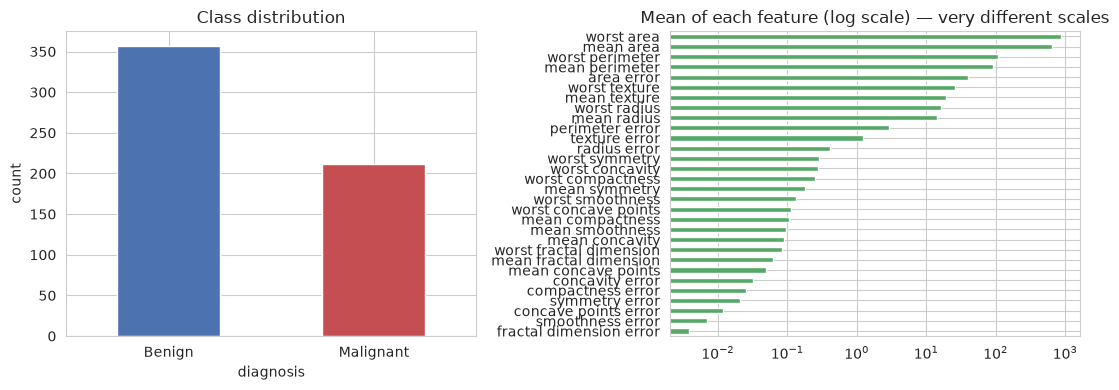

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["diagnosis"].value_counts().plot(kind="bar", ax=axes[0], color=["#4c72b0", "#c44e52"], rot=0)
axes[0].set_title("Class distribution")
axes[0].set_ylabel("count")

# scale difference between features -> motivates standardization
df[feature_cols].describe().loc["mean"].sort_values().plot(kind="barh", ax=axes[1], logx=True, color="#55a868")
axes[1].set_title("Mean of each feature (log scale) — very different scales")
plt.tight_layout(); plt.show()

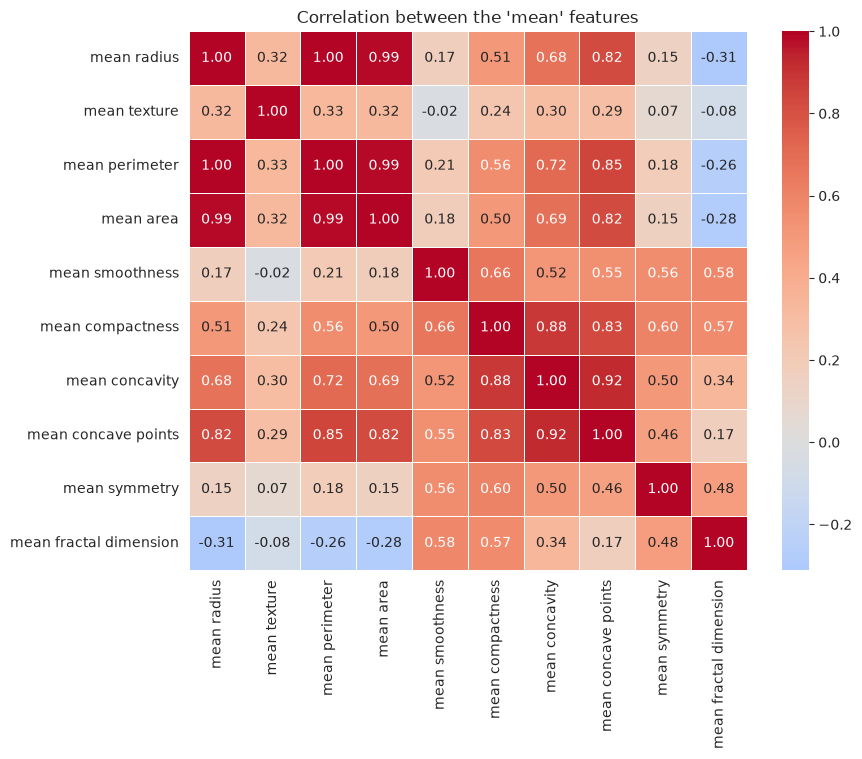

In [9]:
# Correlation heat-map of the 10 "mean" features
mean_cols = [c for c in feature_cols if c.startswith("mean ")]
plt.figure(figsize=(9, 7))
sns.heatmap(df[mean_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5)
plt.title("Correlation between the 'mean' features")
plt.show()

## 3. Data pre-processing

### 3.1 Cleaning checks (missing values, duplicates, outliers)

In [10]:
print("Missing values  :", int(df.isna().sum().sum()))
print("Duplicate rows  :", int(df.duplicated().sum()))

# Outlier count per feature using the IQR rule
Q1, Q3 = df[feature_cols].quantile(.25), df[feature_cols].quantile(.75)
IQR = Q3 - Q1
outliers = ((df[feature_cols] < Q1 - 1.5*IQR) | (df[feature_cols] > Q3 + 1.5*IQR)).sum().sort_values(ascending=False)
print("\nTop 8 features by number of IQR outliers:")
print(outliers.head(8))

Missing values  : 0
Duplicate rows  : 0

Top 8 features by number of IQR outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
dtype: int64


The data has **no missing values and no duplicates**, so no imputation/removal is needed. Several features (e.g. `area error`, `concavity error`) do contain outliers — these are real, informative tumour measurements, so we keep them and use scaling/transformations that handle them instead.

For demonstration, here is how missing values *would* be handled:

In [11]:
from sklearn.impute import SimpleImputer
demo = df[["mean radius", "mean texture"]].head(8).copy()
demo.iloc[2, 0] = np.nan; demo.iloc[5, 1] = np.nan
print("With artificial NaNs:"); display(demo)
imp = SimpleImputer(strategy="mean")
print("After mean-imputation:")
display(pd.DataFrame(imp.fit_transform(demo), columns=demo.columns).round(3))

With artificial NaNs:


,mean radius,mean texture
0,17.99,10.38
1,20.57,17.77
2,NaN,21.25
3,11.42,20.38
4,20.29,14.34
5,12.45,NaN
6,18.25,19.98
7,13.71,20.83


After mean-imputation:


,mean radius,mean texture
0,17.990,10.380
1,20.570,17.770
2,16.383,21.250
3,11.420,20.380
4,20.290,14.340
5,12.450,17.847
6,18.250,19.980
7,13.710,20.830


### 3.2 Standardization / Normalization
| Technique | Formula | Result range | Good when |
|---|---|---|---|
| **Z-score standardization** | z = (x − μ) / σ | mean 0, std 1 (unbounded) | features ~ Gaussian; SVM, KNN, K-Means, PCA |
| **Min-Max normalization** | x′ = (x − min) / (max − min) | [0, 1] | need bounded values; neural nets |
| **Robust scaling** | x′ = (x − median) / IQR | unbounded | data with outliers |
| **Max-abs scaling** | x′ = x / max\|x\| | [−1, 1] | sparse data |
| **Decimal scaling** | x′ = x / 10^j | \|x′\| < 1 | simple textbook method |
| **L2 (row) normalization** | x′ = x / ‖x‖₂ | each row has unit length | cosine-similarity tasks |

**Worked example** on 5 values of `mean area`: 

In [12]:
vals = df["mean area"].head(5).values
mu, sigma = vals.mean(), vals.std(ddof=0)
worked = pd.DataFrame({
    "x": vals,
    "z-score": (vals - mu) / sigma,
    "min-max": (vals - vals.min()) / (vals.max() - vals.min()),
    "decimal (÷10^4)": vals / 1e4,
})
print(f"mean = {mu:.3f}, std = {sigma:.3f}, min = {vals.min()}, max = {vals.max()}")
worked.round(4)

mean = 1042.620, std = 347.415, min = 386.1, max = 1326.0


,x,z-score,min-max,decimal (÷10^4)
0,1001.0,-0.1198,0.6542,0.1001
1,1326.0,0.8157,1.0000,0.1326
2,1203.0,0.4616,0.8691,0.1203
3,386.1,-1.8897,0.0000,0.0386
4,1297.0,0.7322,0.9691,0.1297


In [13]:
X = df[feature_cols]

scalers = {
    "Original": None,
    "StandardScaler (z-score)": StandardScaler(),
    "MinMaxScaler [0,1]": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
    "MaxAbsScaler": MaxAbsScaler(),
}
scaled = {}
for name, sc in scalers.items():
    scaled[name] = X.copy() if sc is None else pd.DataFrame(sc.fit_transform(X), columns=feature_cols)

# Compare the effect on three differently-scaled features
show = ["mean area", "mean smoothness", "mean radius"]
rows = []
for name, d in scaled.items():
    for f in show:
        rows.append([name, f, d[f].min(), d[f].max(), d[f].mean(), d[f].std()])
pd.DataFrame(rows, columns=["method", "feature", "min", "max", "mean", "std"]).round(3)

,method,feature,min,max,mean,std
0,Original,mean area,143.500,2501.000,654.889,351.914
1,Original,mean smoothness,0.053,0.163,0.096,0.014
2,Original,mean radius,6.981,28.110,14.127,3.524
3,StandardScaler (z-score),mean area,-1.454,5.251,-0.000,1.001
4,StandardScaler (z-score),mean smoothness,-3.112,4.771,-0.000,1.001
5,StandardScaler (z-score),mean radius,-2.030,3.971,-0.000,1.001
6,"MinMaxScaler [0,1]",mean area,0.000,1.000,0.217,0.149
7,"MinMaxScaler [0,1]",mean smoothness,0.000,1.000,0.395,0.127
8,"MinMaxScaler [0,1]",mean radius,0.000,1.000,0.338,0.167
9,RobustScaler,mean area,-1.125,5.381,0.286,0.971


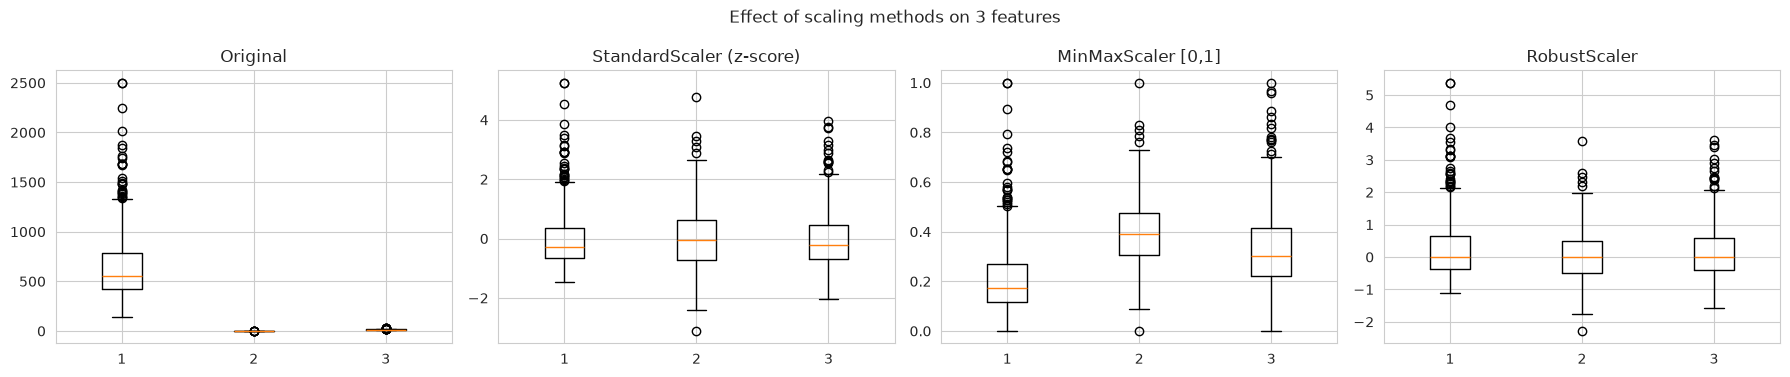

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, name in zip(axes, ["Original", "StandardScaler (z-score)", "MinMaxScaler [0,1]", "RobustScaler"]):
    ax.boxplot([scaled[name][c] for c in show], label=["area", "smooth.", "radius"], showfliers=True)
    ax.set_title(name)
plt.suptitle("Effect of scaling methods on 3 features")
plt.tight_layout(); plt.show()

In [ ]:
# Row-wise L2 normalization (each sample vector gets unit length)
l2 = Normalizer(norm="l2").fit_transform(X)
print("Row norms after L2 normalization (first 5):", np.linalg.norm(l2[:5], axis=1))

# For the rest of the notebook we keep a z-score standardized copy
X_std = pd.DataFrame(StandardScaler().fit_transform(X), columns=feature_cols)
X_mm  = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=feature_cols)

### 3.3 Transformation
Many features are **right-skewed** (long tail of large values). Transformations such as log, square-root, Box-Cox or Yeo-Johnson make the distribution more symmetric, which helps distance- and Gaussian-based algorithms.

In [ ]:
skew = X.skew().sort_values(ascending=False)
print("Most skewed features:")
display(skew.head(8).round(2).to_frame("skewness"))

top = list(skew.index[:4])
transformed = {
    "Original": X[top],
    "log1p":    np.log1p(X[top]),
    "sqrt":     np.sqrt(X[top]),
    "Yeo-Johnson": pd.DataFrame(PowerTransformer(method="yeo-johnson").fit_transform(X[top]), columns=top),
}
print("\nSkewness after each transformation:")
pd.DataFrame({k: v.skew() for k, v in transformed.items()}).round(2)

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for j, name in enumerate(["Original", "log1p", "sqrt", "Yeo-Johnson"]):
    for i, f in enumerate(top[:2]):
        sns.histplot(transformed[name][f], kde=True, ax=axes[i, j], color="#4c72b0")
        axes[i, j].set_title(f"{f}\n{name}  (skew={transformed[name][f].skew():.2f})", fontsize=10)
plt.tight_layout(); plt.show()

In [ ]:
# Yeo-Johnson transform of ALL features (used later for clustering)
X_yj = pd.DataFrame(PowerTransformer(method="yeo-johnson").fit_transform(X), columns=feature_cols)
print("Mean |skew| before:", X.skew().abs().mean().round(3), " after Yeo-Johnson:", X_yj.skew().abs().mean().round(3))

### 3.4 Aggregation
Aggregation summarises data — either **across rows** (group-by) or **across columns** (combine several attributes into one).

In [ ]:
# (a) Row aggregation: summary statistics per diagnosis class
agg_cols = ["mean radius", "mean area", "mean concavity", "mean smoothness"]
df.groupby("diagnosis")[agg_cols].agg(["count", "mean", "median", "std", "min", "max"]).round(3).T

In [ ]:
# (b) Column aggregation: collapse the 3 groups (mean / error / worst) into one feature-group score each.
# Use the standardized data so that all features contribute equally.
groups = {
    "mean_group":  [c for c in feature_cols if c.startswith("mean ")],
    "error_group": [c for c in feature_cols if c.endswith(" error")],
    "worst_group": [c for c in feature_cols if c.startswith("worst ")],
}
agg_df = pd.DataFrame({g: X_std[cols].mean(axis=1) for g, cols in groups.items()})
agg_df["diagnosis"] = df["diagnosis"].values
print({g: len(c) for g, c in groups.items()})
display(agg_df.groupby("diagnosis").mean().round(3))

sns.pairplot(agg_df, hue="diagnosis", palette={"Malignant": "#c44e52", "Benign": "#4c72b0"}, height=2.6, corner=True)
plt.suptitle("Aggregated feature groups", y=1.02); plt.show()

In [ ]:
# (c) Aggregate the 10 base measurements: average of mean / error / worst  (standardized)
base = ["radius", "texture", "perimeter", "area", "smoothness", "compactness", "concavity", "concave points", "symmetry", "fractal dimension"]
base_df = pd.DataFrame({b: X_std[[f"mean {b}", f"{b} error", f"worst {b}"]].mean(axis=1) for b in base})
base_df["diagnosis"] = df["diagnosis"].values
base_df.groupby("diagnosis").mean().T.round(3).sort_values("Malignant", ascending=False)

### 3.5 Discretization & Binarization
**Discretization** converts a continuous attribute into a small number of intervals (bins).

| Method | Idea |
|---|---|
| **Equal-width** | every bin has the same width = (max − min)/k |
| **Equal-frequency (quantile)** | every bin has ≈ the same number of records |
| **K-Means based** | bin edges from 1-D clustering |
| **Custom / domain bins** | cut-points chosen by an expert |

**Binarization** turns a value into 0/1 using a threshold.

In [ ]:
col = "mean radius"
disc = pd.DataFrame({col: df[col]})

disc["equal_width(4)"] = pd.cut(df[col], bins=4, labels=["Low", "Med-Low", "Med-High", "High"])
disc["equal_freq(4)"]  = pd.qcut(df[col], q=4,   labels=["Q1", "Q2", "Q3", "Q4"])
disc["custom"]         = pd.cut(df[col], bins=[0, 12, 15, 18, 100], labels=["Small", "Medium", "Large", "X-Large"])
kb = KBinsDiscretizer(n_bins=4, encode="ordinal", strategy="kmeans")
disc["kmeans(4)"] = kb.fit_transform(df[[col]]).astype(int).ravel()

display(disc.head(8))
print("Bin sizes (count of records):")
display(pd.DataFrame({
    "equal_width": disc["equal_width(4)"].value_counts().sort_index().values,
    "equal_freq":  disc["equal_freq(4)"].value_counts().sort_index().values,
    "custom":      disc["custom"].value_counts().sort_index().values,
    "kmeans":      disc["kmeans(4)"].value_counts().sort_index().values,
}, index=["bin 1", "bin 2", "bin 3", "bin 4"]))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
edges_w = np.linspace(df[col].min(), df[col].max(), 5)
edges_q = df[col].quantile([0, .25, .5, .75, 1]).values
edges_k = kb.bin_edges_[0]
for ax, edges, t in zip(axes, [edges_w, edges_q, edges_k], ["Equal-width", "Equal-frequency", "K-Means bins"]):
    ax.hist(df[col], bins=30, color="#8da0cb")
    for e in edges: ax.axvline(e, color="red", ls="--")
    ax.set_title(f"{t} — {col}")
plt.tight_layout(); plt.show()

In [ ]:
# Binarization: 1 if value is above the threshold (here, the median), else 0
binz = Binarizer(threshold=float(df["mean radius"].median()))
df["radius_above_median"] = binz.fit_transform(df[["mean radius"]]).astype(int)

# Binarize ALL features at their own median (every feature -> 0/1)
X_bin = pd.DataFrame((X > X.median()).astype(int).values, columns=feature_cols)

print(pd.crosstab(df["radius_above_median"], df["diagnosis"], margins=True))

# One-hot encoding of the label, and of a discretised feature
pd.get_dummies(disc["custom"], prefix="size").head()

### 3.6 Sampling
| Technique | Description |
|---|---|
| **Simple random (without replacement)** | every record has the same chance |
| **Stratified** | keeps the class proportions of the population |
| **Systematic** | every *k*-th record |
| **Bootstrap (with replacement)** | resample *n* records with replacement |
| **Under-sampling** | shrink the majority class |
| **Over-sampling** | replicate the minority class |

In [ ]:
def dist(d):
    return d["diagnosis"].value_counts().reindex(["Benign", "Malignant"]).fillna(0).astype(int)

n = 150
simple     = df.sample(n=n, random_state=RANDOM_STATE)
stratified = pd.concat([df[df.diagnosis == c].sample(frac=n/len(df), random_state=RANDOM_STATE) for c in ["Benign", "Malignant"]])
k = len(df) // n
systematic = df.iloc[::k]
bootstrap  = df.sample(n=len(df), replace=True, random_state=RANDOM_STATE)

maj = df[df.diagnosis == "Benign"]; mino = df[df.diagnosis == "Malignant"]
under = pd.concat([resample(maj, replace=False, n_samples=len(mino), random_state=RANDOM_STATE), mino])
over  = pd.concat([maj, resample(mino, replace=True, n_samples=len(maj), random_state=RANDOM_STATE)])

summary = pd.DataFrame({
    "Population": dist(df), "Simple random": dist(simple), "Stratified": dist(stratified),
    "Systematic (every %d-th)" % k: dist(systematic), "Bootstrap": dist(bootstrap),
    "Under-sampled": dist(under), "Over-sampled": dist(over),
}).T
summary["total"] = summary.sum(axis=1)
summary["% Malignant"] = (summary["Malignant"] / summary["total"] * 100).round(1)
summary

*Reading the table:* the stratified sample keeps ≈ 37 % malignant (like the population), whereas simple random/systematic samples drift a little. Under-/over-sampling deliberately force a 50-50 balance — useful when a class is rare. (Here the imbalance is mild, so it is optional.)

## 4. Classification
**Goal:** predict whether a tumour is *Malignant* (positive class = 1) or *Benign* (0).

To avoid **data leakage**, scaling is placed *inside* a `Pipeline`, so the scaler is fitted on the training folds only.

In [ ]:
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Malignant share  train: %.1f%%   test: %.1f%%" % (y_train.mean()*100, y_test.mean()*100))

In [ ]:
models = {
    "KNN (k=5)":            Pipeline([("sc", StandardScaler()), ("m", KNeighborsClassifier(n_neighbors=5))]),
    "Decision Tree":        Pipeline([("sc", StandardScaler()), ("m", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE))]),
    "Naive Bayes":          Pipeline([("sc", StandardScaler()), ("m", GaussianNB())]),
    "Logistic Regression":  Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=1000))]),
    "SVM (RBF)":            Pipeline([("sc", StandardScaler()), ("m", SVC(probability=True, random_state=RANDOM_STATE))]),
    "Random Forest":        Pipeline([("sc", StandardScaler()), ("m", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))]),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results, preds = [], {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test); proba = pipe.predict_proba(X_test)[:, 1]
    preds[name] = p
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall":    recall_score(y_test, p),
        "F1":        f1_score(y_test, p),
        "ROC-AUC":   roc_auc_score(y_test, proba),
        "CV acc (5-fold)": cross_val_score(pipe, X, y, cv=cv).mean(),
    })
res = pd.DataFrame(results).set_index("Model").round(4).sort_values("F1", ascending=False)
res

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, p) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, p)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

**Medical note:** a *false negative* (a malignant tumour predicted benign) is the most costly error, so **recall** for the malignant class matters most, alongside precision and F1.

In [ ]:
best = res.index[0]
print("Best model by F1:", best)
print(classification_report(y_test, preds[best], target_names=["Benign", "Malignant"]))

In [ ]:
# Interpretability: Decision-tree rules and Random-Forest feature importance
tree = models["Decision Tree"]
print(export_text(tree.named_steps["m"], feature_names=feature_cols, max_depth=3))

rf = models["Random Forest"].named_steps["m"]
imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False).head(10)
imp.sort_values().plot(kind="barh", figsize=(7, 4), color="#55a868", title="Top-10 Random Forest feature importances")
plt.show()

In [ ]:
# Does pre-processing matter?  Compare WITH vs WITHOUT scaling (5-fold CV accuracy)
algos = {
    "KNN":  KNeighborsClassifier(n_neighbors=5),
    "SVM":  SVC(),
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}
rows = []
for n_, m in algos.items():
    raw  = cross_val_score(m, X, y, cv=cv).mean()
    std_ = cross_val_score(Pipeline([("s", StandardScaler()), ("m", m)]), X, y, cv=cv).mean()
    mm_  = cross_val_score(Pipeline([("s", MinMaxScaler()),  ("m", m)]), X, y, cv=cv).mean()
    yj_  = cross_val_score(Pipeline([("s", PowerTransformer()), ("m", m)]), X, y, cv=cv).mean()
    rows.append([n_, raw, std_, mm_, yj_])
cmp = pd.DataFrame(rows, columns=["Algorithm", "No scaling", "Standardized", "Min-Max", "Yeo-Johnson+Std"]).set_index("Algorithm").round(4)
cmp

*Distance-based models (KNN, SVM) benefit most from scaling; tree-based models are almost unaffected because splits depend only on the ordering of values.*

## 5. Clustering — K-Means
K-Means partitions *n* points into *k* clusters by repeating two steps until the centroids stop moving:
1. **Assign** each point to its nearest centroid (Euclidean distance).
2. **Update** each centroid = mean of the points assigned to it.

It minimises the **inertia** (WCSS) = Σ ‖xᵢ − μ_cluster(i)‖².

Clustering is **unsupervised** — we hide the diagnosis labels while clustering, then use them only afterwards to check how well the clusters match.

### 5.1 Dry run on a tiny 2-D example (k = 2)

In [ ]:
pts = np.array([[1, 1], [1.5, 2], [3, 4], [5, 7], [3.5, 5], [4.5, 5], [3.5, 4.5]])
names = list("ABCDEFG")
centroids = pts[[0, 3]].astype(float)          # start with A and D
print("Initial centroids:", centroids.tolist())

for it in range(1, 6):
    d = np.linalg.norm(pts[:, None, :] - centroids[None, :, :], axis=2)
    assign = d.argmin(axis=1)
    print(f"\n--- Iteration {it} ---")
    display(pd.DataFrame(d.round(2), index=names, columns=["dist→C1", "dist→C2"]).assign(cluster=assign + 1))
    new_c = np.array([pts[assign == j].mean(axis=0) for j in range(2)])
    print("New centroids:", new_c.round(3).tolist())
    if np.allclose(new_c, centroids):
        print("Centroids did not change → converged."); break
    centroids = new_c

plt.figure(figsize=(5, 4))
plt.scatter(pts[:, 0], pts[:, 1], c=assign, cmap="coolwarm", s=90)
for (x_, y_), n_ in zip(pts, names): plt.annotate(n_, (x_+.08, y_+.08))
plt.scatter(*centroids.T, marker="X", s=200, c="black", label="centroids"); plt.legend(); plt.title("Toy example — final clusters")
plt.show()

### 5.2 K-Means implemented from scratch (NumPy)

In [ ]:
def kmeans_scratch(X, k, max_iter=300, tol=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.asarray(X, dtype=float)
    centroids = X[rng.choice(len(X), size=k, replace=False)]
    inertia_hist = []
    for it in range(max_iter):
        dist = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)   # (n, k)
        labels = dist.argmin(axis=1)                                          # assignment step
        inertia_hist.append((dist[np.arange(len(X)), labels] ** 2).sum())
        new_c = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centroids[j] for j in range(k)])
        shift = np.linalg.norm(new_c - centroids)                              # update step
        centroids = new_c
        if shift < tol:
            break
    return labels, centroids, inertia_hist, it + 1

labels_s, cent_s, hist, n_iter = kmeans_scratch(X_std.values, k=2, seed=1)
print("Converged in", n_iter, "iterations")
print("Cluster sizes:", np.bincount(labels_s))
plt.plot(range(1, len(hist)+1), hist, marker="o"); plt.xlabel("iteration"); plt.ylabel("inertia (WCSS)")
plt.title("From-scratch K-Means: inertia per iteration"); plt.show()

### 5.3 Choosing k — elbow method & silhouette score

In [ ]:
ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_std)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_std, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertias, "o-"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia")
axes[1].plot(list(ks), sils, "o-", color="green"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print("Best k by silhouette:", list(ks)[int(np.argmax(sils))])

### 5.4 K-Means with k = 2 (matches the two diagnoses) and comparison with the true labels

In [ ]:
km = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(X_std)
df["cluster"] = km.labels_

ct = pd.crosstab(df["cluster"], df["diagnosis"])
print("Cluster vs. true diagnosis:"); display(ct)

# Map each cluster to the majority class to compute a purity-style accuracy
mapping = ct.idxmax(axis=1).to_dict()
mapped = df["cluster"].map(mapping)
purity = (mapped == df["diagnosis"]).mean()

metrics = pd.Series({
    "Silhouette score": silhouette_score(X_std, km.labels_),
    "Adjusted Rand Index": adjusted_rand_score(df["label"], km.labels_),
    "Homogeneity": homogeneity_score(df["label"], km.labels_),
    "Purity (cluster→majority class)": purity,
    "Inertia": km.inertia_,
}).round(4)
display(metrics.to_frame("value"))

# From-scratch result vs. scikit-learn
print("Agreement between from-scratch and sklearn labels (ARI):", round(adjusted_rand_score(labels_s, km.labels_), 4))

In [ ]:
# Visualise clusters in 2-D with PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X_std)
cent_Z = pca.transform(km.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(Z[:, 0], Z[:, 1], c=km.labels_, cmap="coolwarm", s=22, alpha=.8)
axes[0].scatter(*cent_Z.T, marker="X", s=250, c="black"); axes[0].set_title("K-Means clusters (k=2)")
axes[1].scatter(Z[:, 0], Z[:, 1], c=df["label"], cmap="coolwarm", s=22, alpha=.8); axes[1].set_title("True diagnosis (red = Malignant)")
for ax in axes: ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.tight_layout(); plt.show()
print("Variance explained by 2 PCs: %.1f%%" % (pca.explained_variance_ratio_.sum()*100))

In [ ]:
# Does pre-processing change clustering quality?  (k = 2)
variants = {
    "Raw (no scaling)": X,
    "Z-score": X_std,
    "Min-Max": X_mm,
    "Yeo-Johnson + Z": X_yj,
}
rows = []
for name, data in variants.items():
    m = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(data)
    rows.append([name, silhouette_score(data, m.labels_), adjusted_rand_score(df["label"], m.labels_)])
pd.DataFrame(rows, columns=["Pre-processing", "Silhouette", "ARI vs diagnosis"]).set_index("Pre-processing").round(4)

In [ ]:
# Cluster profiles: average of the original (unscaled) features per cluster
df.groupby("cluster")[["mean radius", "mean area", "mean concavity", "mean texture", "worst perimeter"]].mean().round(2)

## 6. Association rules — support, confidence & lift
Association rule mining finds patterns of the form **A ⇒ B** ("if A then B") in *transactions* made of binary items.

| Measure | Formula | Meaning |
|---|---|---|
| **Support(A)** | count(A) / N | how frequent the itemset is |
| **Support(A ⇒ B)** | count(A ∪ B) / N | how often A and B occur together |
| **Confidence(A ⇒ B)** | support(A ∪ B) / support(A) | P(B \| A) — reliability of the rule |
| **Lift(A ⇒ B)** | confidence / support(B) | > 1 positive association, = 1 independent, < 1 negative |

**Preparing the data:** continuous features must first be **discretized** into Low / Medium / High (equal-frequency bins), then turned into binary items (one-hot). The diagnosis becomes two more items.

In [ ]:
# --- Build the transaction table -----------------------------------------------------------
items_feats = ["mean radius", "mean texture", "mean area", "mean smoothness",
               "mean concavity", "mean symmetry", "worst perimeter", "worst concave points"]
short = {"mean radius": "radius", "mean texture": "texture", "mean area": "area", "mean smoothness": "smooth",
         "mean concavity": "concav", "mean symmetry": "symm", "worst perimeter": "w_perim", "worst concave points": "w_cpts"}

trans = pd.DataFrame(index=df.index)
for f in items_feats:
    b = pd.qcut(df[f], q=3, labels=["Low", "Med", "High"])
    for lvl in ["Low", "Med", "High"]:
        trans[f"{short[f]}={lvl}"] = (b == lvl)
trans["Dx=Malignant"] = df["diagnosis"] == "Malignant"
trans["Dx=Benign"]    = df["diagnosis"] == "Benign"
trans = trans.astype(bool)

print("Transaction matrix:", trans.shape, "(rows = patients, columns = items)")
trans.head()

### 6.1 Worked example — support & confidence of one rule by hand

In [ ]:
A = trans["w_perim=High"]
B = trans["Dx=Malignant"]
N = len(trans)

cnt_A, cnt_B, cnt_AB = A.sum(), B.sum(), (A & B).sum()
support_A   = cnt_A / N
support_B   = cnt_B / N
support_AB  = cnt_AB / N
confidence  = support_AB / support_A
lift        = confidence / support_B

print(f"Rule:  worst perimeter = High   ⇒   Diagnosis = Malignant")
print(f"N = {N},  count(A) = {cnt_A},  count(B) = {cnt_B},  count(A and B) = {cnt_AB}")
print(f"support(A)      = {cnt_A}/{N} = {support_A:.4f}")
print(f"support(A ⇒ B)  = {cnt_AB}/{N} = {support_AB:.4f}")
print(f"confidence      = support(A∪B)/support(A) = {support_AB:.4f}/{support_A:.4f} = {confidence:.4f}")
print(f"lift            = confidence/support(B)   = {confidence:.4f}/{support_B:.4f} = {lift:.4f}")

### 6.2 Apriori algorithm (implemented from scratch)

**Apriori principle:** *every subset of a frequent itemset must itself be frequent.* So we
1. find frequent 1-itemsets (support ≥ min_support),
2. join them to make candidate 2-itemsets, count, prune, and repeat for 3-itemsets, …
3. generate rules from the frequent itemsets and keep those with confidence ≥ min_confidence.

In [ ]:
from itertools import combinations

def apriori_scratch(onehot, min_support=0.1, max_len=3):
    N = len(onehot)
    cols = list(onehot.columns)
    M = onehot.values
    support = {}
    # L1
    current = {}
    for j, c in enumerate(cols):
        s = M[:, j].mean()
        if s >= min_support:
            current[frozenset([c])] = s
    support.update(current)
    k = 2
    while current and k <= max_len:
        prev = list(current.keys())
        # candidate generation by joining (k-1)-itemsets
        cands = set()
        for a, b in combinations(prev, 2):
            u = a | b
            if len(u) == k:
                # prune: all (k-1)-subsets must be frequent
                if all(frozenset(sub) in current for sub in combinations(u, k - 1)):
                    cands.add(u)
        current = {}
        for c in cands:
            idx = [cols.index(i) for i in c]
            s = M[:, idx].all(axis=1).mean()
            if s >= min_support:
                current[c] = s
        support.update(current)
        k += 1
    return support

def rules_from(support, min_conf=0.7):
    rows = []
    for itemset, s_ab in support.items():
        if len(itemset) < 2: continue
        for r in range(1, len(itemset)):
            for ante in combinations(itemset, r):
                ante = frozenset(ante); cons = itemset - ante
                conf = s_ab / support[ante]
                lift = conf / support[cons]
                if conf >= min_conf:
                    rows.append({"antecedent": ", ".join(sorted(ante)), "consequent": ", ".join(sorted(cons)),
                                 "support": s_ab, "confidence": conf, "lift": lift})
    return pd.DataFrame(rows)

freq = apriori_scratch(trans, min_support=0.15, max_len=3)
freq_df = (pd.DataFrame({"itemset": [", ".join(sorted(k)) for k in freq], "length": [len(k) for k in freq], "support": list(freq.values())})
           .sort_values("support", ascending=False))
print("Frequent itemsets found:", len(freq_df), " (by length:", freq_df.length.value_counts().sort_index().to_dict(), ")")
freq_df.head(12).round(4)

In [ ]:
rules = rules_from(freq, min_conf=0.8)
print("Rules with confidence ≥ 0.80:", len(rules))

# Rules that predict the diagnosis
dx_rules = rules[rules["consequent"].isin(["Dx=Malignant", "Dx=Benign"])]
dx_rules = dx_rules[dx_rules["lift"] > 1].sort_values(["confidence", "lift", "support"], ascending=False)
dx_rules.head(15).round(4).reset_index(drop=True)

In [ ]:
# Strongest rules for each class
for cls in ["Dx=Malignant", "Dx=Benign"]:
    sub = dx_rules[dx_rules["consequent"] == cls].head(5)
    print(f"\nTop rules predicting {cls}:")
    for _, r in sub.iterrows():
        print(f"  IF {r.antecedent:<45} THEN {cls}   (support={r.support:.3f}, confidence={r.confidence:.3f}, lift={r.lift:.2f})")

In [ ]:
# Support vs confidence scatter (colour = lift)
plt.figure(figsize=(7, 5))
sc = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=40, alpha=.8)
plt.colorbar(sc, label="lift"); plt.xlabel("support"); plt.ylabel("confidence"); plt.title("Association rules")
plt.show()

In [ ]:
# (Optional) cross-check with the mlxtend library — it is pre-installed on Google Colab
try:
    from mlxtend.frequent_patterns import apriori, association_rules
    fi = apriori(trans, min_support=0.15, use_colnames=True, max_len=3)
    ar = association_rules(fi, metric="confidence", min_threshold=0.8)
    print("mlxtend frequent itemsets:", len(fi), "| scratch:", len(freq_df))
    print("mlxtend rules (conf ≥ 0.8):", len(ar), "| scratch:", len(rules))
except ImportError:
    print("mlxtend not installed — run  !pip install mlxtend  to enable this cross-check.")

## 7. Summary

| Stage | What we did | Key takeaway |
|---|---|---|
| **EDA** | 569 samples, 30 features, 37 % malignant | No missing values/duplicates; features on very different scales; many highly correlated |
| **Standardization / Normalization** | z-score, min-max, robust, max-abs, decimal, L2 | Essential for KNN, SVM, K-Means; irrelevant for trees |
| **Transformation** | log, sqrt, Yeo-Johnson | Reduced right-skew of area/perimeter/error features |
| **Aggregation** | group-by diagnosis; mean/error/worst group scores | Malignant tumours score much higher on size & shape groups |
| **Discretization / Binarization** | equal-width, equal-frequency, k-means, custom bins; median threshold | Needed to create items for association rules |
| **Sampling** | random, stratified, systematic, bootstrap, under/over | Stratified sampling preserves class balance |
| **Classification** | KNN, Decision Tree, Naive Bayes, LogReg, SVM, Random Forest | Scaled SVM / Logistic Regression / KNN reach ≈ 96-97 % test accuracy (SVM best, F1 ≈ 0.96); the unpruned-depth-4 tree is weakest; recall on malignant is the metric to watch |
| **K-Means** | scratch implementation + sklearn, elbow & silhouette | k = 2 is the best silhouette choice; clusters match the diagnosis ≈ 90 % (ARI ≈ 0.65) without ever seeing the labels |
| **Association rules** | support, confidence, lift via Apriori | Large size/concavity values ⇒ Malignant; small values ⇒ Benign, with high confidence |

**Possible extensions:** hyper-parameter tuning with `GridSearchCV`, feature selection (correlation filter / PCA), hierarchical clustering & DBSCAN, SMOTE for balancing.